# Agrupamiento de líneas celulares de cáncer mediante K-means y clustering jerárquico

**Objetivo.** Aprender a resolver problemas de aprendizaje **no supervisado** mediante dos métodos de *clustering*:

1. **K-means clustering** — primero lo implementamos *desde cero* sobre un dataset sintético para entender cada paso del algoritmo, y después lo aplicamos con `scikit-learn` a un problema real (expresión génica de líneas celulares de cáncer, **NCI60**).
2. **Hierarchical clustering** — lo aplicamos al mismo dataset NCI60, comparando distintas **métricas de disimilitud** y **métodos de *linkage***.

En cada sección explicamos **qué** vamos a hacer, **por qué** lo hacemos y **qué indican** los resultados.

### Contenido
- **Parte 1.** K-means desde cero (dataset sintético)
- **Parte 2.** K-means en NCI60 (PCA, selección de *k*, interpretación)
- **Parte 3.** Hierarchical clustering en NCI60 y comparación con K-means

## 0. Configuración del entorno

El tutorial está pensado para ejecutarse en **Google Colab**. Solo necesitamos instalar la librería `ISLP` (*An Introduction to Statistical Learning with Python*), que contiene el dataset NCI60. El resto de librerías (`numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`) ya vienen instaladas en Colab.

> Si `ISLP` ya está instalada en tu entorno, puedes omitir la siguiente celda.

In [91]:
!pip install -q ISLP

zsh:1: command not found: pip


Importamos todas las librerías que usaremos a lo largo del tutorial y fijamos una **semilla** (`SEED`) para que los resultados sean reproducibles.

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from ISLP import load_data

SEED = 10
plt.rcParams['figure.figsize'] = (7, 5)
sns.set_style('whitegrid')

---
# Parte 1. K-means (dataset sintético)

## 1.1 ¿Qué es *clustering*?

El *clustering* es un conjunto de técnicas para **encontrar grupos (clusters) en un conjunto de datos** sin usar etiquetas. Buscamos que:

- las observaciones **dentro de un mismo grupo** sean **muy similares** entre sí, y
- las observaciones de **grupos distintos** sean **muy diferentes**.

Es un problema **no supervisado**: no existe una variable respuesta $y$ que el modelo deba predecir; el algoritmo descubre la estructura únicamente a partir de las variables $X$.

Para entender bien cómo funciona K-means, en esta parte lo programaremos paso a paso sobre datos sintéticos, donde **sabemos** cuántos grupos existen y podemos verificar si el algoritmo los recupera.

## 1.2 Creación del dataset sintético

**Qué hacemos.** Generamos un dataset con `make_blobs()` con las siguientes características:

| Parámetro | Valor |
|---|---|
| Muestras (`n_samples`) | 1000 |
| Centros (`centers`) | 3 |
| Variables (`n_features`) | 2 |
| Desviación estándar (`cluster_std`) | 1.5 |

**Por qué.** Con datos sintéticos conocemos la "respuesta correcta" (3 grupos), así que podemos comprobar visualmente si el algoritmo funciona. Usar 2 variables nos permite graficar todo en un plano.

`make_blobs()` devuelve también las etiquetas reales (`y_real`), pero **no las usaremos para graficar ni para agrupar**: en un problema no supervisado real esas etiquetas no existirían.

In [93]:
X, y_real = make_blobs(n_samples=1000, centers=3, n_features=2,
                       cluster_std=1.5, random_state=SEED)

print('Dimensiones de X:', X.shape)
pd.DataFrame(X, columns=['feature_1', 'feature_2']).describe().round(2)

Dimensiones de X: (1000, 2)


,feature_1,feature_2
count,1000.00,1000.00
mean,2.67,-3.39
std,2.72,6.30
min,-4.70,-14.05
25%,0.59,-8.75
50%,2.58,-5.61
75%,4.84,3.96
max,9.45,9.17


Graficamos *feature 1* vs *feature 2* **sin colores por etiqueta**, que es exactamente lo que vería un analista que no conoce los grupos.

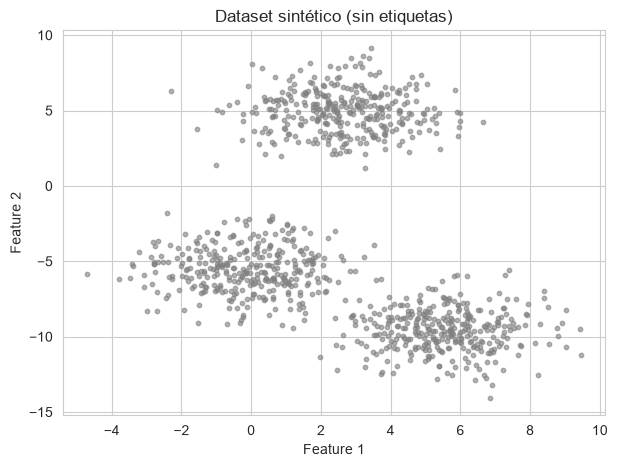

In [94]:
plt.scatter(X[:, 0], X[:, 1], s=10, color='gray', alpha=0.6)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Dataset sintético (sin etiquetas)')
plt.show()

**¿Qué indica la gráfica?** A simple vista se distinguen **tres nubes de puntos**: una arriba, separada del resto, y dos abajo que **casi se tocan** en la zona central. Hay una estructura de grupos clara, ideal para probar K-means, pero la frontera entre las dos nubes de abajo será la parte difícil. El reto del algoritmo será encontrar esos tres grupos **sin que se los digamos**.

## 1.3 Teoría: el objetivo de K-means

K-means divide las $n$ observaciones en $K$ clusters $C_1, \dots, C_K$ **disjuntos** (cada observación pertenece exactamente a un cluster). Un buen agrupamiento es aquel en el que la **variación dentro de cada cluster** (*within-cluster variation*, WCV) es lo más pequeña posible.

Usando distancia Euclidiana al cuadrado, la variación dentro del cluster $k$ se define como:

$$
W(C_k) = \frac{1}{|C_k|} \sum_{i,\,i' \in C_k} \sum_{j=1}^{p} \left(x_{ij} - x_{i'j}\right)^2
= 2 \sum_{i \in C_k} \sum_{j=1}^{p} \left(x_{ij} - \bar{x}_{kj}\right)^2
$$

donde $\bar{x}_{kj}$ es la media de la variable $j$ en el cluster $k$ (el **centroide**). K-means busca resolver:

$$
\underset{C_1,\dots,C_K}{\text{minimizar}} \; \sum_{k=1}^{K} W(C_k)
$$

Encontrar el mínimo exacto es computacionalmente inviable (hay casi $K^n$ formas de particionar los datos), por lo que se usa un **algoritmo iterativo** que encuentra un **óptimo local**:

1. **Inicialización:** asignar aleatoriamente un número de cluster (de 1 a $K$) a cada observación.
2. **Iterar hasta que las asignaciones dejen de cambiar:**
   - (a) Calcular el **centroide** de cada cluster: el vector de medias de las $p$ variables.
   - (b) **Reasignar** cada observación al cluster cuyo centroide esté más cerca (distancia Euclidiana).

Cada iteración **nunca aumenta** el objetivo, por lo que el algoritmo siempre converge. En las siguientes secciones implementamos cada paso.

> En el código medimos la WCV como la suma de distancias al cuadrado de cada punto a su centroide (la versión de la derecha de la ecuación sin el factor 2). Como solo difiere por una constante, sirve igual para comparar soluciones.

## 1.4 Asignación aleatoria inicial

**Qué hacemos.** Fijamos $K = 3$ y asignamos a cada observación, al azar, una etiqueta 0, 1 o 2. Usamos un generador con **semilla** para que el resultado sea reproducible.

**Por qué.** Es el paso 1 del algoritmo: K-means necesita un punto de partida. Al ser aleatorio, todavía no tiene relación con la estructura real de los datos.

In [95]:
K = 3
rng = np.random.default_rng(SEED)            # generador con semilla -> reproducible
etiquetas = rng.integers(0, K, size=X.shape[0])

print('Observaciones por cluster:', np.bincount(etiquetas))

Observaciones por cluster: [343 331 326]


Definimos una función para graficar los datos coloreados por cluster (y, opcionalmente, los centroides). La reutilizaremos en todas las iteraciones.

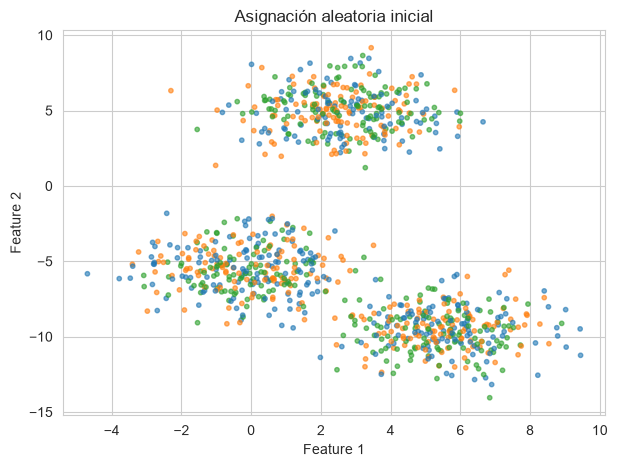

In [96]:
COLORES = np.array(['tab:blue', 'tab:orange', 'tab:green'])

def graficar_clusters(X, etiquetas, centroides=None, titulo=''):
    plt.scatter(X[:, 0], X[:, 1], c=COLORES[etiquetas], s=10, alpha=0.6)
    if centroides is not None:
        plt.scatter(centroides[:, 0], centroides[:, 1], c=COLORES[:len(centroides)],
                    marker='X', s=250, edgecolor='black', linewidth=1.5)
        plt.scatter([], [], marker='X', s=150, c='white', edgecolor='black', label='Centroides')
        plt.legend()
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title(titulo)
    plt.show()

graficar_clusters(X, etiquetas, titulo='Asignación aleatoria inicial')

**¿Qué indica la gráfica?** Los tres colores están **completamente mezclados** en las tres nubes: la asignación inicial no tiene ninguna relación con la estructura de los datos, y cada cluster tiene aproximadamente un tercio de las observaciones. Este es el punto de partida "malo" del cual el algoritmo deberá recuperarse.

## 1.5 Cálculo de centroides

**Qué hacemos.** Calculamos el centroide de cada cluster: el vector que contiene la **media de cada variable** para las observaciones de ese cluster,

$$
\bar{x}_k = \left( \frac{1}{|C_k|}\sum_{i \in C_k} x_{i1}, \; \dots, \; \frac{1}{|C_k|}\sum_{i \in C_k} x_{ip} \right).
$$

**Por qué.** Es el paso 2(a) del algoritmo. El centroide es el "representante" de cada cluster y será la referencia para reasignar las observaciones.

También definimos la función que calcula la WCV total, para medir qué tan buena es cada solución.

> **Detalle de implementación: clusters vacíos.** Como los centroides iniciales quedan muy juntos, puede ocurrir que en una reasignación **ningún punto** quede más cerca de alguno de ellos. Ese cluster queda vacío y su media no está definida (`NaN`), lo que rompería el algoritmo. Las implementaciones reales (como `scikit-learn`) lo resuelven reubicando el centroide; aquí lo reubicamos en una observación elegida al azar.

Centroides iniciales:
 [[ 2.649 -3.7  ]
 [ 2.606 -3.335]
 [ 2.748 -3.128]]
WCV inicial: 46,969.3


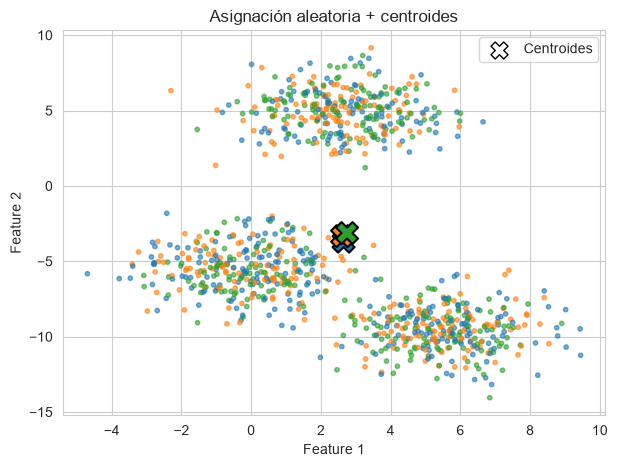

In [97]:
def calcular_centroides(X, etiquetas, K):
    centroides = []
    for k in range(K):
        if np.any(etiquetas == k):
            centroides.append(X[etiquetas == k].mean(axis=0))
        else:
            # cluster vacío: su media no existe, así que lo reubicamos en una observación al azar
            centroides.append(X[np.random.default_rng().integers(len(X))])
            print(f'⚠ El cluster {k} quedó vacío; su centroide se reubicó en una observación aleatoria.')
    return np.array(centroides)

def wcv_total(X, etiquetas, centroides):
    # suma de distancias euclidianas al cuadrado de cada punto a su centroide
    return sum(((X[etiquetas == k] - centroides[k]) ** 2).sum() for k in range(len(centroides)))

centroides = calcular_centroides(X, etiquetas, K)
print('Centroides iniciales:\n', centroides.round(3))
print(f'WCV inicial: {wcv_total(X, etiquetas, centroides):,.1f}')

graficar_clusters(X, etiquetas, centroides, titulo='Asignación aleatoria + centroides')

**¿Qué indican los resultados?** Los tres centroides quedan **amontonados cerca del centro global** de los datos. Es lógico: como cada cluster contiene puntos tomados al azar de las tres nubes, la media de cada uno se parece a la media general. La WCV inicial es muy alta porque los puntos están lejos de "su" centroide.

## 1.6 Paso *update*: reasignar y recalcular

**Qué hacemos.** Implementamos el paso 2(b) y volvemos a calcular los centroides:

1. Para cada observación calculamos la **distancia Euclidiana** a cada uno de los $K$ centroides: $d(x_i, \bar{x}_k) = \sqrt{\sum_{j=1}^{p}(x_{ij} - \bar{x}_{kj})^2}$.
2. La reasignamos al cluster **más cercano**.
3. Recalculamos los centroides con las nuevas etiquetas.

**Por qué así.** La celda de *update* está escrita para **poder iterarse**: no crea un dataset nuevo, sino que **actualiza** las variables `etiquetas` y `centroides` que ya tenemos. Así, cada vez que se ejecuta avanza una iteración del algoritmo.

Primero definimos la función de reasignación y un contador de iteraciones:

In [98]:
def asignar_cluster_mas_cercano(X, centroides):
    # distancias de cada punto (n) a cada centroide (K) -> matriz n x K
    distancias = np.sqrt(((X[:, np.newaxis, :] - centroides[np.newaxis, :, :]) ** 2).sum(axis=2))
    return distancias.argmin(axis=1)

iteracion = 0
historial_wcv = [wcv_total(X, etiquetas, centroides)]

### ▶ Celda de *update* (ejecútala varias veces)

**Ejecuta la siguiente celda repetidamente** (`Shift + Enter` y vuelve a ella). En cada ejecución verás cuántas observaciones cambiaron de cluster y cómo baja la WCV. Cuando el número de cambios sea **0**, el algoritmo habrá **convergido**.

Iteración 2: 24 observaciones cambiaron de cluster | WCV = 4,168.0


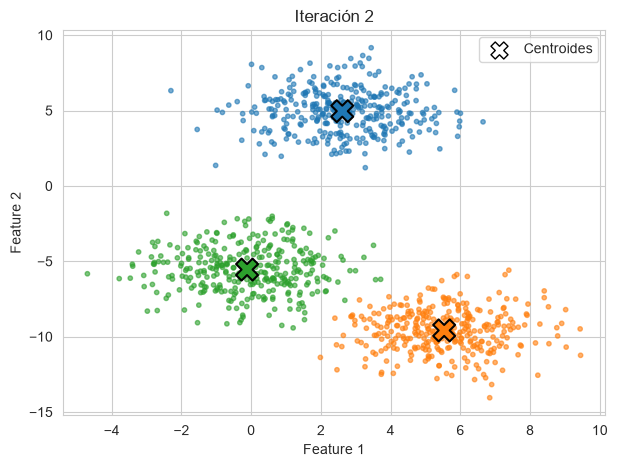

In [127]:
# ---------- UPDATE: reasignar etiquetas y recalcular centroides ----------
etiquetas_nuevas = asignar_cluster_mas_cercano(X, centroides)
cambios = int((etiquetas_nuevas != etiquetas).sum())

etiquetas = etiquetas_nuevas                       # actualizamos (no creamos datos nuevos)
centroides = calcular_centroides(X, etiquetas, K)
iteracion += 1
historial_wcv.append(wcv_total(X, etiquetas, centroides))

print(f'Iteración {iteracion}: {cambios} observaciones cambiaron de cluster | WCV = {historial_wcv[-1]:,.1f}')
if cambios == 0:
    print('✔ Convergencia: las asignaciones ya no cambian.')

graficar_clusters(X, etiquetas, centroides, titulo=f'Iteración {iteracion}')

**¿Qué indican los resultados?** Con la semilla `SEED = 10` observamos lo siguiente al ejecutar la celda varias veces:

- **Iteración 1:** 648 de las 1000 observaciones cambian de cluster. La nube de arriba queda casi completa en un solo cluster, pero las dos nubes de abajo todavía están mal repartidas: un cluster se queda con solo una franja pequeña y otro abarca las dos nubes.
- **Iteraciones 2–3:** siguen cambiando muchas observaciones (183 y luego 89). Los centroides de abajo se van separando hasta que cada uno se coloca en una nube.
- **Iteraciones 4–5:** solo cambian unos pocos puntos de la frontera (14 y luego 2). La WCV baja hasta ≈ **4,167.5**.
- **Iteración 6:** **0 cambios** → el algoritmo convergió. Cada color corresponde a una de las tres nubes y cada centroide queda en el centro de su nube.

Como las dos nubes de abajo están más cerca entre sí, el algoritmo necesitó **más iteraciones** para separarlas bien.

Esto ilustra la propiedad clave del algoritmo: **la WCV disminuye en cada iteración** hasta que las asignaciones se estabilizan. Podemos visualizar esa evolución:

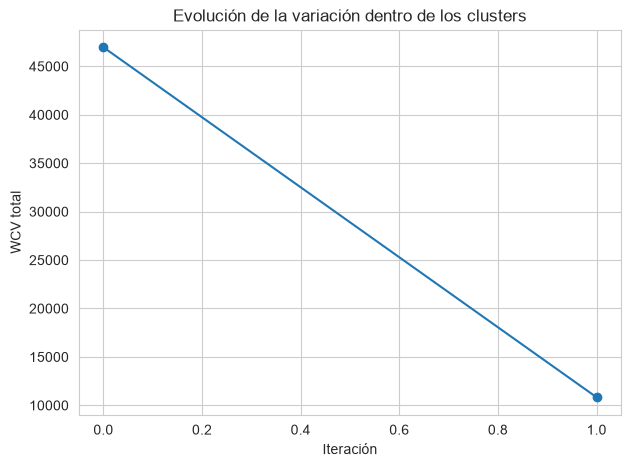

In [100]:
plt.plot(range(len(historial_wcv)), historial_wcv, 'o-')
plt.xlabel('Iteración')
plt.ylabel('WCV total')
plt.title('Evolución de la variación dentro de los clusters')
plt.show()

**¿Qué indica la gráfica?** La WCV cae drásticamente en la primera iteración y después se aplana: el algoritmo hace casi todo el trabajo al inicio y las iteraciones siguientes solo refinan las fronteras. *(Esta gráfica muestra tantos puntos como veces hayas ejecutado la celda de update).*

Como verificación, comparamos los clusters encontrados contra las etiquetas reales de `make_blobs` (que hasta ahora no habíamos usado). Los números de cluster son arbitrarios, así que lo importante es que cada cluster corresponda a **un solo** grupo real:

In [101]:
pd.crosstab(pd.Series(y_real, name='Grupo real'),
            pd.Series(etiquetas, name='Cluster K-means'))

Cluster K-means,0,1,2
Grupo real,,,
0,334,0,0
1,0,0,333
2,285,47,1


**¿Qué indica la tabla?** Cada cluster de K-means coincide uno a uno con un grupo real: de 1000 observaciones, **solo 4** quedan en un cluster distinto al de su grupo de origen. Son puntos de la zona donde las dos nubes de abajo se tocan, así que es razonable que queden del otro lado. K-means **recuperó la estructura** sin haber visto nunca las etiquetas.

## 1.7 Estocasticidad del algoritmo

**Qué hacemos.** Regresamos al punto de la asignación aleatoria inicial, **eliminamos la semilla** y repetimos el proceso.

**Por qué.** K-means encuentra un **óptimo local**, no necesariamente el global. El resultado depende de la asignación inicial aleatoria, así que queremos ver qué pasa cuando cambia el punto de partida.

La siguiente celda reinicia el algoritmo **sin semilla** (cada ejecución dará una asignación inicial distinta):

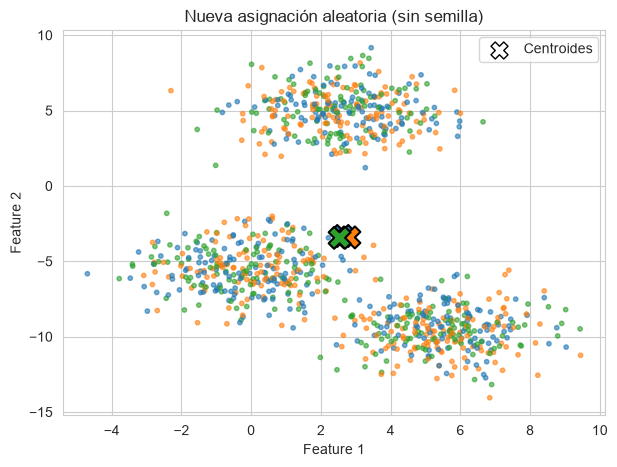

In [102]:
rng = np.random.default_rng()                 # SIN semilla -> distinto en cada ejecución
etiquetas = rng.integers(0, K, size=X.shape[0])
centroides = calcular_centroides(X, etiquetas, K)
iteracion = 0
historial_wcv = [wcv_total(X, etiquetas, centroides)]

graficar_clusters(X, etiquetas, centroides, titulo='Nueva asignación aleatoria (sin semilla)')

### ▶ Celda de *update* sin semilla (ejecútala varias veces hasta 0 cambios)

Iteración 1: 656 cambios | WCV = 4,780.7
Centroides:
 [[ 2.6   4.94]
 [ 5.65 -9.46]
 [-0.03 -5.78]]


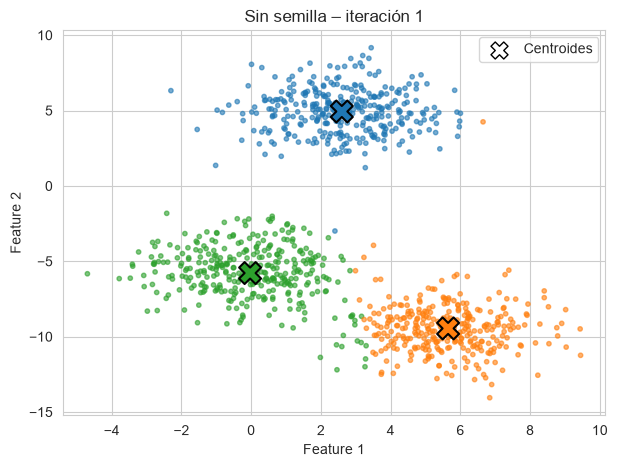

In [103]:
etiquetas_nuevas = asignar_cluster_mas_cercano(X, centroides)
cambios = int((etiquetas_nuevas != etiquetas).sum())
etiquetas = etiquetas_nuevas
centroides = calcular_centroides(X, etiquetas, K)
iteracion += 1
historial_wcv.append(wcv_total(X, etiquetas, centroides))

print(f'Iteración {iteracion}: {cambios} cambios | WCV = {historial_wcv[-1]:,.1f}')
print('Centroides:\n', centroides.round(2))
if cambios == 0:
    print('✔ Convergencia')

graficar_clusters(X, etiquetas, centroides, titulo=f'Sin semilla – iteración {iteracion}')

**¿Qué indican los resultados?** Al repetir el proceso varias veces sin semilla observamos que:

- El **número de iteraciones** hasta converger cambia (en nuestras pruebas, casi siempre entre 4 y 8, y a veces más).
- En algunas corridas aparece el aviso de **cluster vacío** en la primera iteración: con centroides iniciales tan juntos, uno de ellos puede no "ganar" ningún punto. El centroide se reubica y el algoritmo continúa normalmente.
- Los **números de cluster cambian** (la nube que antes era el cluster 0 ahora puede ser el 2). Esto es normal: las etiquetas son arbitrarias, lo que importa es la partición.
- La gran mayoría de las veces el algoritmo llega a la **misma partición** (WCV ≈ 4,167.5). Pero **no siempre**: en algunas corridas queda atrapado en una solución peor (lo vemos en la siguiente celda).

Que el resultado dependa del inicio es el precio de que K-means solo garantice un **óptimo local**. Por eso, en la práctica:

1. Se corre el algoritmo **múltiples veces**, cada una desde una asignación inicial distinta.
2. Se elige la solución con el **objetivo (WCV) más pequeño**.

Esto es exactamente lo que hace el parámetro `n_init` de `KMeans` en `scikit-learn`, que usaremos en la Parte 2.

In [104]:
# Ejemplo: varias corridas completas sin semilla, guardando la WCV final de cada una
def kmeans_manual(X, K, rng, max_iter=100):
    etq = rng.integers(0, K, size=X.shape[0])
    for it in range(1, max_iter + 1):
        cent = calcular_centroides(X, etq, K)
        nuevas = asignar_cluster_mas_cercano(X, cent)
        if (nuevas == etq).all():
            break
        etq = nuevas
    return etq, calcular_centroides(X, etq, K), it

rng = np.random.default_rng()
wcv_corridas = []
for corrida in range(1, 21):
    etq, cent, it = kmeans_manual(X, K, rng)
    wcv_corridas.append(wcv_total(X, etq, cent))
    print(f'Corrida {corrida:2d}: {it:2d} iteraciones | WCV final = {wcv_corridas[-1]:,.1f}')

print(f'\nMejor WCV: {min(wcv_corridas):,.1f} | Peor WCV: {max(wcv_corridas):,.1f}')

Corrida  1:  6 iteraciones | WCV final = 4,167.5
Corrida  2:  6 iteraciones | WCV final = 4,167.5
Corrida  3:  4 iteraciones | WCV final = 4,167.5
Corrida  4:  7 iteraciones | WCV final = 11,755.1
Corrida  5:  5 iteraciones | WCV final = 4,167.5
Corrida  6:  6 iteraciones | WCV final = 4,167.5
Corrida  7:  6 iteraciones | WCV final = 4,167.5
Corrida  8:  6 iteraciones | WCV final = 4,167.5
Corrida  9: 10 iteraciones | WCV final = 11,755.1
Corrida 10:  7 iteraciones | WCV final = 4,167.5
Corrida 11:  5 iteraciones | WCV final = 4,167.5
⚠ El cluster 2 quedó vacío; su centroide se reubicó en una observación aleatoria.
Corrida 12:  7 iteraciones | WCV final = 4,167.5
Corrida 13:  6 iteraciones | WCV final = 4,167.5
Corrida 14:  7 iteraciones | WCV final = 4,167.5
Corrida 15:  6 iteraciones | WCV final = 4,167.5
Corrida 16:  7 iteraciones | WCV final = 4,167.5
Corrida 17:  7 iteraciones | WCV final = 4,167.5
Corrida 18:  5 iteraciones | WCV final = 4,167.5
Corrida 19:  5 iteraciones | WCV f

**¿Qué indica la salida?** *(Los números cambian en cada ejecución porque no hay semilla.)*
- La mayoría de las corridas termina con WCV ≈ **4,167.5**: la solución correcta, con una nube en cada cluster.
- En nuestras pruebas, alrededor de **1 de cada 15 corridas** termina con WCV ≈ **11,700**, casi el triple. Es un **óptimo local malo**: el algoritmo parte una nube en dos clusters y junta otras dos nubes en un solo cluster. Ya no puede salir de ahí porque ninguna reasignación individual mejora la WCV. Si en tus 20 corridas no aparece, vuelve a ejecutar la celda.
- Por eso se corre varias veces y **se queda la de menor WCV**: aunque alguna corrida falle, la mejor de 20 casi seguro es la correcta.

La función `kmeans_manual` es, en esencia, lo que `KMeans(n_init=...)` repite internamente para quedarse con la mejor solución.

### Conclusiones de la Parte 1
- K-means alterna dos pasos — **calcular centroides** y **reasignar al centroide más cercano** — y la WCV nunca aumenta, por lo que siempre converge.
- Converge a un **óptimo local** que depende de la inicialización aleatoria; por eso se ejecuta varias veces y se conserva la solución con menor WCV.
- Requiere **fijar $K$ de antemano**. Aquí sabíamos que $K = 3$; en la Parte 2 veremos cómo elegirlo cuando no lo sabemos.

---
# Parte 2. K-means en un caso real: NCI60

Ya sabemos cómo funciona K-means por dentro. Ahora lo usamos en datos reales con `KMeans` de `scikit-learn`.

## 2.1 El dataset NCI60

**Qué es.** NCI60 contiene la **expresión de 6,830 genes** medida en **64 líneas celulares de cáncer**. Cada fila es una línea celular y cada columna es un gen. Un valor alto significa que ese gen está muy "activo" en esa célula.

**Por qué es interesante.** Cada línea celular tiene una etiqueta con su tipo de cáncer, pero **no la vamos a usar para agrupar**. La idea es ver si K-means, solo mirando los genes, forma grupos que se parezcan a los tipos de cáncer. Al final usaremos las etiquetas únicamente para revisar los resultados.

In [105]:
nci = load_data('NCI60')
X_nci = pd.DataFrame(nci['data'], columns=[f'gen_{i}' for i in range(nci['data'].shape[1])])
etiquetas_cancer = nci['labels']['label']

print('Shape de los datos:', X_nci.shape)
X_nci.iloc[:5, :8]

Shape de los datos: (64, 6830)


,gen_0,gen_1,gen_2,gen_3,gen_4,gen_5,gen_6,gen_7
0,0.300000,1.180000,0.550000,1.140000,-0.265000,-7.000000e-02,0.350000,-0.315000
1,0.679961,1.289961,0.169961,0.379961,0.464961,5.799610e-01,0.699961,0.724961
2,0.940000,-0.040000,-0.170000,-0.040000,-0.605000,0.000000e+00,0.090000,0.645000
3,0.280000,-0.310000,0.680000,-0.810000,0.625000,-1.387779e-17,0.170000,0.245000
4,0.485000,-0.465000,0.395000,0.905000,0.200000,-5.000000e-03,0.085000,0.110000


Revisamos cuántas líneas celulares hay de cada tipo de cáncer:

In [106]:
etiquetas_cancer.value_counts()

label
RENAL          9
NSCLC          9
MELANOMA       8
BREAST         7
COLON          7
OVARIAN        6
LEUKEMIA       6
CNS            5
PROSTATE       2
UNKNOWN        1
K562B-repro    1
K562A-repro    1
MCF7A-repro    1
MCF7D-repro    1
Name: count, dtype: int64

**¿Qué vemos?**
- Tenemos **muchas más variables (6,830) que observaciones (64)**. Esto es muy común en datos genéticos y hace difícil visualizar o agrupar directamente.
- Hay **14 etiquetas**, pero varias tienen muy pocas muestras. `K562A-repro`, `K562B-repro`, `MCF7A-repro` y `MCF7D-repro` son **réplicas** de líneas de leucemia (K562) y de mama (MCF7), y `UNKNOWN` es una muestra sin tipo conocido.
- Los tipos más comunes (renal, pulmón NSCLC, melanoma, mama, colon) tienen entre 7 y 9 muestras.

## 2.2 K-means directo sobre los genes

**Qué hacemos.** Primero **estandarizamos** los datos (media 0 y desviación estándar 1 en cada gen) y aplicamos `KMeans` con 3, 4 y 5 clusters.

**Por qué estandarizar.** K-means usa distancias. Si un gen varía mucho más que otro, dominaría la distancia solo por su escala. Al estandarizar, todos los genes pesan lo mismo.

**Parámetros importantes de `KMeans`:**
- `n_clusters`: el número de clusters $k$.
- `n_init=50`: corre el algoritmo **50 veces** con distintos inicios aleatorios y se queda con la mejor solución (menor WCV). Es justo lo que vimos en la Parte 1.
- `random_state`: semilla para que el resultado sea reproducible.

In [107]:
X_nci_esc = StandardScaler().fit_transform(X_nci)

resultados_genes = {}
for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X_nci_esc)
    resultados_genes[k] = km
    sil = silhouette_score(X_nci_esc, km.labels_)
    print(f'k = {k} | WCV = {km.inertia_:,.0f} | silhouette = {sil:.3f} | tamaño de cada cluster: {np.bincount(km.labels_)}')

k = 3 | WCV = 372,243 | silhouette = 0.078 | tamaño de cada cluster: [36  9 19]
k = 4 | WCV = 351,498 | silhouette = 0.080 | tamaño de cada cluster: [ 7 23 25  9]
k = 5 | WCV = 336,847 | silhouette = 0.077 | tamaño de cada cluster: [13 30  9  7  5]


> En `scikit-learn`, la WCV se llama `inertia_`. El **silhouette** lo explicamos en la sección 2.4; por ahora basta saber que va de −1 a 1 y que **más alto = clusters mejor separados**.

Ahora intentamos **ver** los clusters. Como no podemos graficar 6,830 dimensiones, graficamos algunos pares de genes. Elegimos los **4 genes con mayor varianza** (en los datos originales), porque son los que más cambian entre líneas celulares y, por lo tanto, los que más podrían mostrar diferencias entre grupos. Coloreamos con la solución de $k = 4$.

Genes con mayor varianza: ['gen_4700', 'gen_4699', 'gen_6392', 'gen_255']


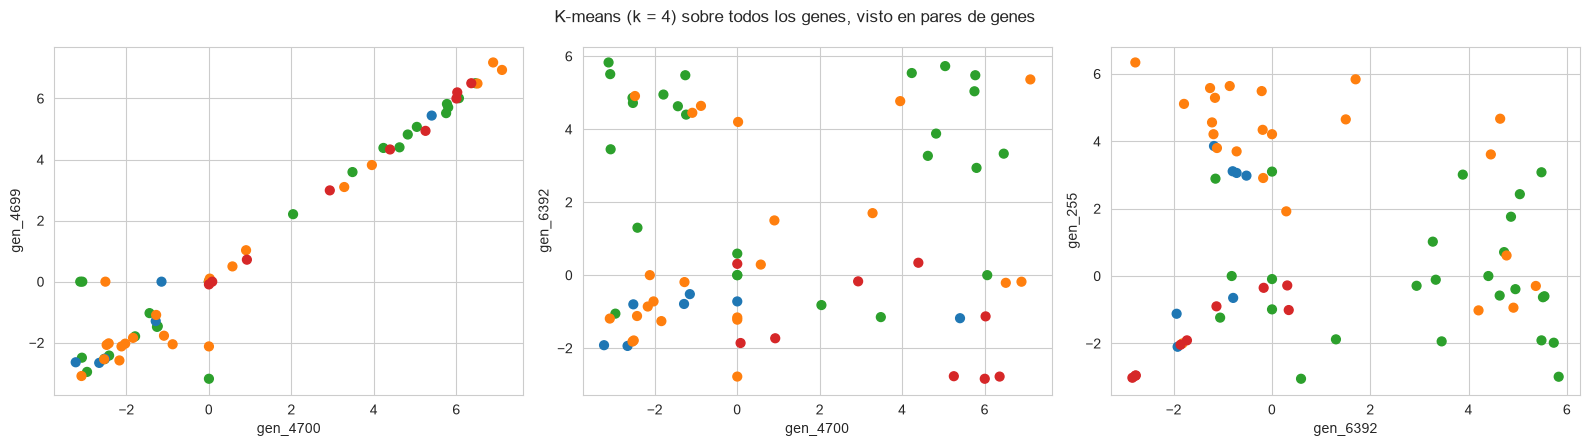

In [108]:
genes_top = X_nci.var().sort_values(ascending=False).index[:4]
print('Genes con mayor varianza:', list(genes_top))

clusters_k4_genes = resultados_genes[4].labels_
pares = [(genes_top[0], genes_top[1]), (genes_top[0], genes_top[2]), (genes_top[2], genes_top[3])]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (g1, g2) in zip(axes, pares):
    sc = ax.scatter(X_nci[g1], X_nci[g2], c=clusters_k4_genes, cmap='tab10', vmin=0, vmax=9, s=40)
    ax.set_xlabel(g1)
    ax.set_ylabel(g2)
fig.suptitle('K-means (k = 4) sobre todos los genes, visto en pares de genes')
plt.tight_layout()
plt.show()

**¿Qué vemos?**
- En la primera gráfica los puntos forman casi una **línea recta**: `gen_4700` y `gen_4699` están muy correlacionados, así que cuentan casi la misma historia. Ver dos genes así no nos ayuda a separar grupos.
- En las otras dos gráficas algunos clusters se separan **en parte** (por ejemplo, en `gen_6392` vs `gen_255`), pero ningún par separa los 4 grupos de forma limpia y varios colores se encuentran mezclados.
- Esto **no significa que K-means esté mal**: los clusters se formaron usando los 6,830 genes a la vez, y aquí solo vemos 2. Es como intentar entender una escultura mirando únicamente su sombra.
- Además, con tantas variables, mucha de la información es **ruido** (genes que varían sin relación con el tipo de cáncer), lo cual dificulta encontrar grupos.

Necesitamos una forma de **resumir** los 6,830 genes en pocas variables que conserven la mayor parte de la información. Para eso usamos PCA.

## 2.3 Preprocesamiento con PCA

**Qué es PCA.** El Análisis de Componentes Principales crea nuevas variables, llamadas **componentes principales (PCs)**, que son combinaciones de los genes originales:
- **PC1** es la dirección en la que los datos **varían más**.
- **PC2** es la siguiente dirección con más variación (y no está correlacionada con PC1), y así sucesivamente.

**Por qué usarlo antes de K-means.**
1. Reduce miles de variables a unas cuantas → podemos **graficar** los datos.
2. Los primeros PCs concentran la **señal** y los últimos suelen ser **ruido**, así que agrupar con pocos PCs suele dar clusters más claros.

Aplicamos PCA sobre los datos estandarizados (PCA también depende de la escala de cada variable).

In [109]:
pca = PCA()
pcs = pca.fit_transform(X_nci_esc)
print('Shape de los componentes:', pcs.shape)   # máximo 64 PCs porque solo hay 64 observaciones

Shape de los componentes: (64, 64)


### Gráficas PC1 vs PC2, PC1 vs PC3 y PC2 vs PC3

Graficamos los primeros tres componentes **sin colores**, para intentar estimar a ojo cuántos grupos hay.

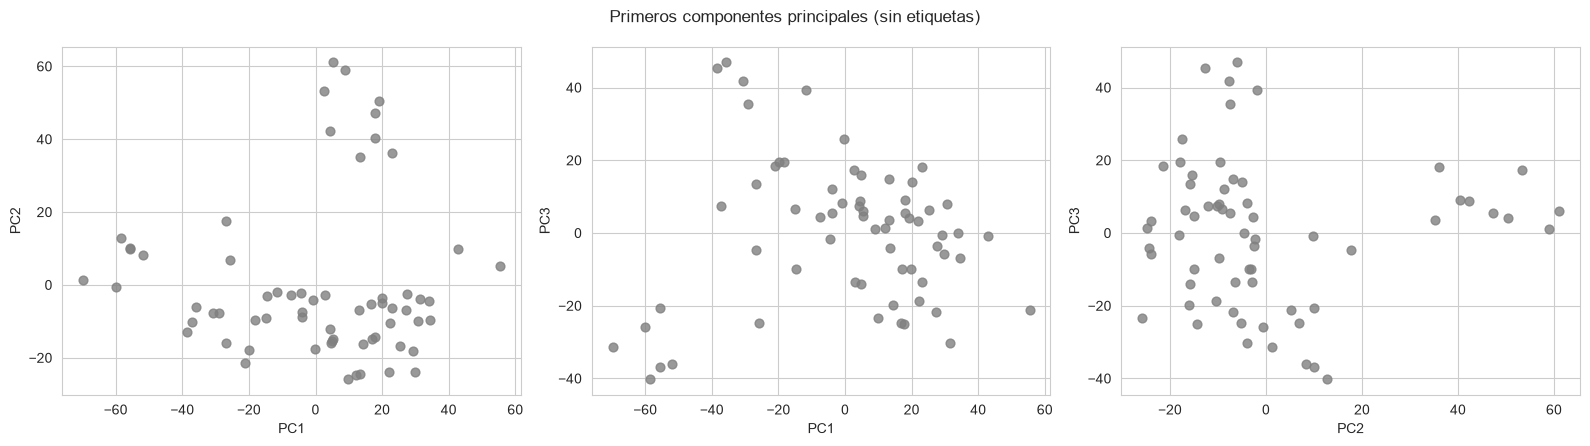

In [110]:
pares_pc = [(0, 1), (0, 2), (1, 2)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (a, b) in zip(axes, pares_pc):
    ax.scatter(pcs[:, a], pcs[:, b], color='gray', s=40, alpha=0.8)
    ax.set_xlabel(f'PC{a+1}')
    ax.set_ylabel(f'PC{b+1}')
fig.suptitle('Primeros componentes principales (sin etiquetas)')
plt.tight_layout()
plt.show()

**¿Qué vemos?**
- A diferencia de los pares de genes, aquí sí aparecen **zonas más densas** y algunos puntos alejados del resto.
- En **PC1 vs PC2** se ve un grupo grande en la parte de abajo, un grupo pequeño **arriba** (PC2 alto) y otro grupo pequeño a la **izquierda** (PC1 muy negativo).
- En **PC1 vs PC3** el grupo de la izquierda vuelve a aparecer separado (abajo a la izquierda), y el grupo grande parece estirarse en dos partes. En **PC2 vs PC3** el grupo de PC2 alto queda claramente aparte.
- A ojo, parece haber **entre 3 y 4 grupos**. Esto coincide con el rango de 3 a 5 clusters que vamos a probar. Más adelante lo confirmamos con métricas.

### ¿Cuántos componentes conservamos?

Cada PC explica un porcentaje de la variación total de los datos. Graficamos:
- **Varianza explicada por cada PC** (*scree plot*): buscamos el **codo**, el punto donde la curva deja de caer rápido y se aplana. Después del codo, cada PC nuevo aporta poco.
- **Varianza explicada acumulada**: cuánta información total llevamos al sumar PCs.

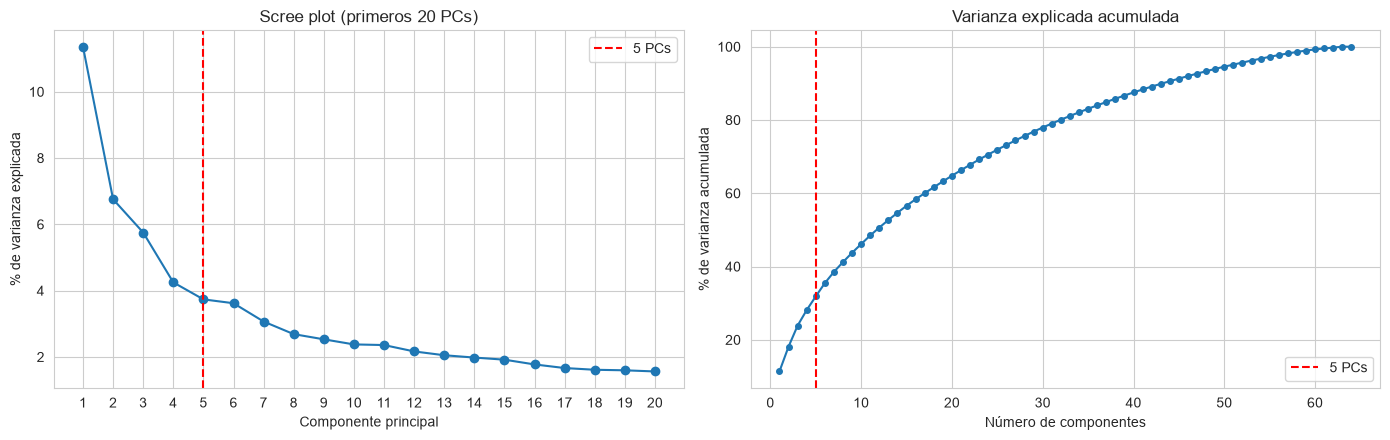

,% varianza,% acumulado
PC1,11.36,11.4
PC2,6.76,18.1
PC3,5.75,23.9
PC4,4.25,28.1
PC5,3.73,31.8
PC6,3.62,35.5
PC7,3.07,38.5
PC8,2.69,41.2


In [111]:
var_exp = pca.explained_variance_ratio_ * 100
var_acum = np.cumsum(var_exp)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, 21), var_exp[:20], 'o-')
axes[0].axvline(5, color='red', linestyle='--', label='5 PCs')
axes[0].set_xlabel('Componente principal')
axes[0].set_ylabel('% de varianza explicada')
axes[0].set_title('Scree plot (primeros 20 PCs)')
axes[0].set_xticks(range(1, 21))
axes[0].legend()

axes[1].plot(range(1, len(var_acum) + 1), var_acum, 'o-', markersize=4)
axes[1].axvline(5, color='red', linestyle='--', label='5 PCs')
axes[1].set_xlabel('Número de componentes')
axes[1].set_ylabel('% de varianza acumulada')
axes[1].set_title('Varianza explicada acumulada')
axes[1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'% varianza': var_exp[:8].round(2), '% acumulado': var_acum[:8].round(1)},
             index=[f'PC{i}' for i in range(1, 9)])

**¿Qué vemos?**
- **PC1** explica ≈ 11.4% de la variación, **PC2** ≈ 6.8%, **PC3** ≈ 5.8% y **PC4** ≈ 4.3%. Hasta aquí la curva cae rápido.
- A partir de **PC5** (≈ 3.7%) la curva se **aplana**: cada componente extra aporta muy poco y casi lo mismo que el anterior. Ese es el **codo**.
- Por eso conservamos **5 componentes**, que juntos explican ≈ **31.8%** de la variación.

**¿No es muy poco 31.8%?** En datos genéticos es normal: hay miles de genes y gran parte de su variación es ruido o diferencias muy específicas de cada muestra. Lo importante es que esos 5 PCs capturan las **diferencias más fuertes** entre líneas celulares, que son las que nos interesan para formar grupos.

In [112]:
N_PCS = 5
pcs_sel = pcs[:, :N_PCS]
print('Datos para K-means:', pcs_sel.shape)

Datos para K-means: (64, 5)


## 2.4 K-means con los componentes principales

### Elegir el número de clusters

**Qué hacemos.** Corremos K-means sobre los 5 PCs con $k = 3, 4, 5$ y comparamos dos métricas:
- **WCV (`inertia_`)**: qué tan compactos son los clusters. **Siempre baja** al aumentar $k$ (con $k = n$ sería 0), así que no basta con elegir la más baja; buscamos dónde deja de bajar mucho.
- **Silhouette**: para cada punto compara qué tan cerca está de su propio cluster contra el cluster vecino más cercano. Va de −1 a 1; **más alto = clusters más separados y mejor definidos**.

In [113]:
filas = []
modelos_pca = {}
for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(pcs_sel)
    modelos_pca[k] = km
    filas.append({'k': k,
                  'WCV': round(km.inertia_),
                  'Silhouette': round(silhouette_score(pcs_sel, km.labels_), 3),
                  'Tamaños': np.bincount(km.labels_).tolist()})

tabla_k = pd.DataFrame(filas).set_index('k')
tabla_k

,WCV,Silhouette,Tamaños
k,,,
3,77570,0.332,"[34, 9, 21]"
4,57917,0.340,"[27, 7, 9, 21]"
5,45518,0.348,"[4, 9, 8, 15, 28]"


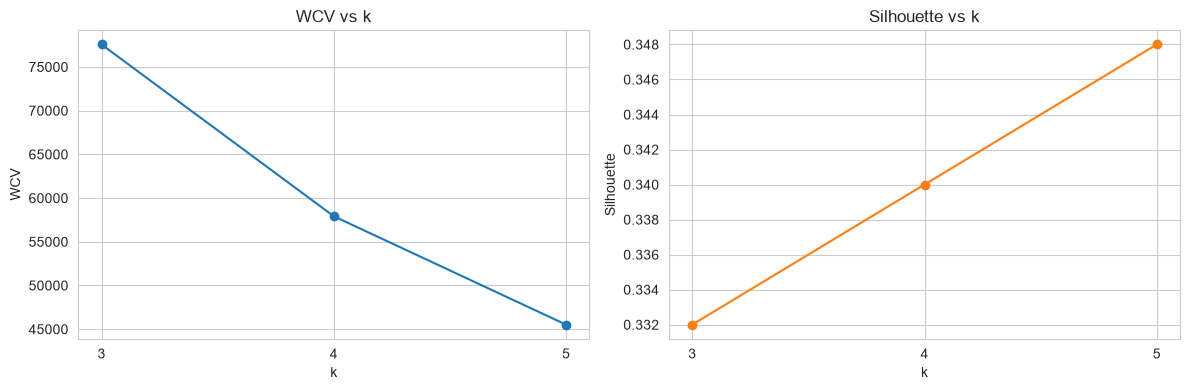

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tabla_k.index, tabla_k['WCV'], 'o-')
axes[0].set_xlabel('k'); axes[0].set_ylabel('WCV'); axes[0].set_title('WCV vs k')
axes[0].set_xticks([3, 4, 5])
axes[1].plot(tabla_k.index, tabla_k['Silhouette'], 'o-', color='tab:orange')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette'); axes[1].set_title('Silhouette vs k')
axes[1].set_xticks([3, 4, 5])
plt.tight_layout()
plt.show()

**¿Qué vemos?**
- La **WCV** baja de forma casi constante (≈ 77.6 mil → 57.9 mil → 45.5 mil). No hay un codo claro, así que por sí sola no decide.
- El **silhouette** mejora un poco al pasar de 3 a 4 clusters (0.332 → 0.340) y casi nada al pasar a 5 (0.348).
- Comparado con K-means sobre todos los genes (silhouette ≈ 0.08), usar PCA da clusters **mucho mejor definidos**.

**Elegimos $k = 4$.** Es el mejor balance: casi el mismo silhouette que $k = 5$, pero con grupos más grandes y fáciles de interpretar. Además, como veremos en la sección 2.5, con $k = 4$ la leucemia queda en su propio cluster, mientras que con $k = 3$ se mezcla con otros tipos de cáncer.

### Visualizar los clusters

Graficamos los mismos pares de componentes de antes, ahora coloreados por cluster.

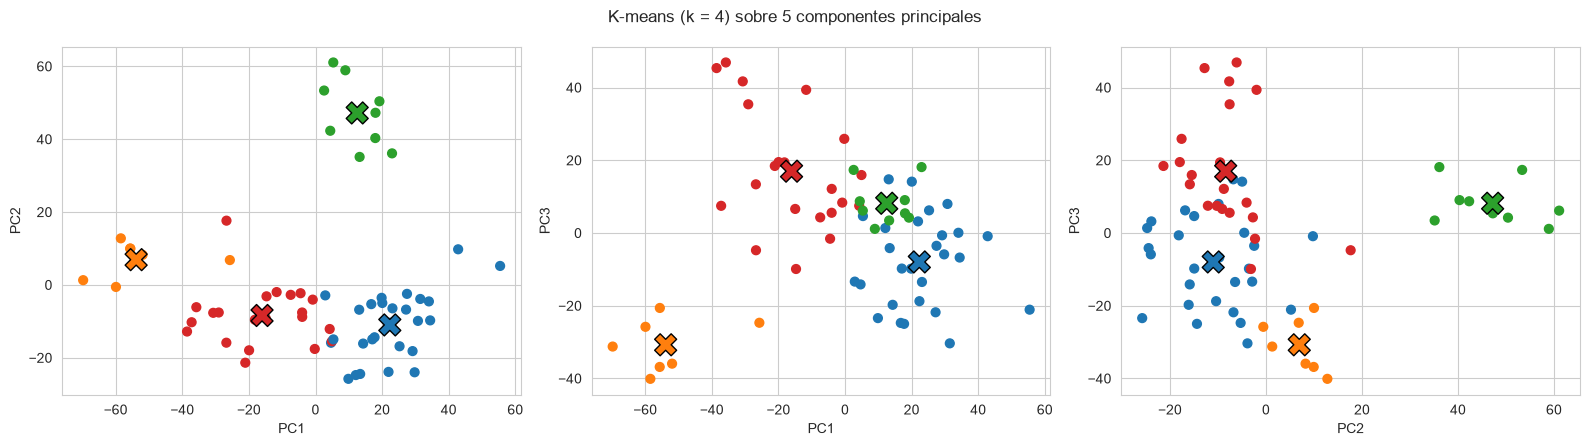

In [115]:
K_FINAL = 4
clusters_km = modelos_pca[K_FINAL].labels_
centros_km = modelos_pca[K_FINAL].cluster_centers_

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (a, b) in zip(axes, pares_pc):
    ax.scatter(pcs_sel[:, a], pcs_sel[:, b], c=clusters_km, cmap='tab10', vmin=0, vmax=9, s=40)
    ax.scatter(centros_km[:, a], centros_km[:, b], c=range(K_FINAL), cmap='tab10', vmin=0, vmax=9,
               marker='X', s=250, edgecolor='black')
    ax.set_xlabel(f'PC{a+1}')
    ax.set_ylabel(f'PC{b+1}')
fig.suptitle(f'K-means (k = {K_FINAL}) sobre {N_PCS} componentes principales')
plt.tight_layout()
plt.show()

**¿Qué vemos?**
- Ahora los colores sí forman **regiones mucho más claras** que con los pares de genes.
- Los dos grupos pequeños que vimos a ojo quedaron cada uno en **su propio cluster**: el de PC2 alto y el de PC1 muy negativo.
- El grupo grande se **dividió en dos clusters** (uno a la izquierda y otro a la derecha en PC1). En PC1 vs PC3 se nota que esa división tiene sentido, porque uno de ellos se va hacia valores altos de PC3.
- Algunos puntos de colores distintos se ven encimados. Recuerda que el agrupamiento usó **5 PCs**, y aquí solo vemos 2 a la vez: puntos que parecen cercanos en una gráfica pueden estar lejos en otro componente.

## 2.5 Interpretación de los clusters

### Tabla de tipos de cáncer vs clusters

**Qué hacemos.** Ahora sí usamos las etiquetas reales: contamos cuántas líneas celulares de cada tipo de cáncer cayeron en cada cluster.

**Por qué.** Nos dice si los grupos que encontró K-means (sin ver las etiquetas) tienen sentido biológico.

In [116]:
tabla_km = pd.crosstab(etiquetas_cancer, clusters_km, rownames=['Tipo de cáncer'], colnames=['Cluster'])
tabla_km

Cluster,0,1,2,3
Tipo de cáncer,,,,
BREAST,3,0,2,2
CNS,5,0,0,0
COLON,0,0,0,7
K562A-repro,0,1,0,0
K562B-repro,0,1,0,0
LEUKEMIA,0,5,0,1
MCF7A-repro,0,0,0,1
MCF7D-repro,0,0,0,1
MELANOMA,1,0,7,0


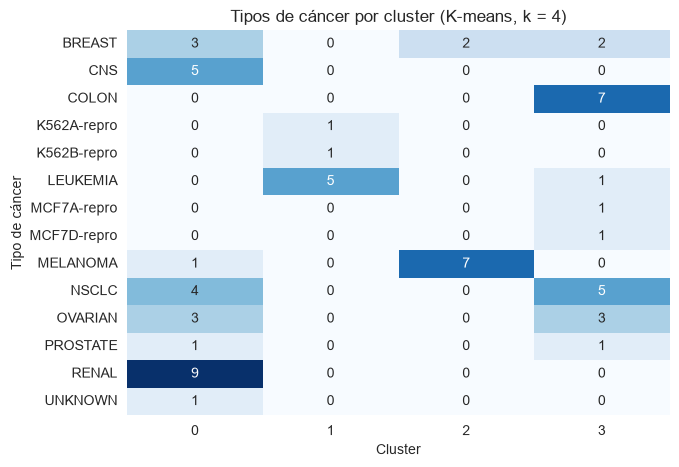

In [117]:
sns.heatmap(tabla_km, annot=True, cmap='Blues', cbar=False)
plt.title(f'Tipos de cáncer por cluster (K-means, k = {K_FINAL})')
plt.show()

**¿Qué vemos?** *(Los números de cluster pueden cambiar entre versiones de `scikit-learn`; lo importante es qué tipos de cáncer quedan juntos.)*
- Un cluster es casi exclusivamente **melanoma** (7 de las 8 líneas de melanoma, más 2 de mama).
- Otro cluster agrupa **leucemia** (5 de 6) junto con sus réplicas **K562**. Que las réplicas caigan con la leucemia es una buena señal: K-means reconoce que son el mismo tipo de célula.
- Otro cluster reúne **todo colon** (7 de 7), junto con parte de **NSCLC**, **ovario** y las réplicas de mama **MCF7**.
- El cluster más grande reúne **todo renal** (9 de 9) y **todo CNS** (5 de 5), además de parte de NSCLC, ovario y mama.

**Conclusión:** K-means, sin ver nunca las etiquetas, separó tipos de cáncer muy distintos entre sí (melanoma, leucemia). En cambio, tipos como **mama, NSCLC y ovario** quedan repartidos en varios clusters, lo que sugiere que sus perfiles genéticos son más **variados** o se parecen a los de otros tipos.

### Heatmap de los genes más relevantes

**Qué hacemos.** Queremos saber **qué genes** hacen diferentes a los grupos. Para que sea fácil de leer, usamos solo **2 clusters** y seguimos estos pasos:

1. Correr K-means con $k = 2$ sobre los 5 PCs.
2. Calcular la **expresión promedio de cada gen** en cada cluster (con los datos **originales**, para que las diferencias estén en las unidades reales de expresión).
3. Calcular la **diferencia absoluta** entre los dos promedios para cada gen.
4. Quedarnos con los **40 genes** con mayor diferencia.
5. **Estandarizar** esos 40 genes, para que todos usen la misma escala de colores.
6. **Ordenar** las líneas celulares por cluster y graficar el heatmap.

In [118]:
# 1. K-means con 2 clusters
km2 = KMeans(n_clusters=2, n_init=50, random_state=SEED).fit(pcs_sel)
clusters_2 = km2.labels_
print('Tamaño de cada cluster:', np.bincount(clusters_2))

# 2. Expresión promedio por cluster (datos originales)
promedios = X_nci.groupby(clusters_2).mean()

# 3. Diferencia absoluta entre clusters por gen
diferencia = (promedios.loc[0] - promedios.loc[1]).abs()

# 4. Los 40 genes con mayor diferencia
N_GENES = 40
genes_relevantes = diferencia.sort_values(ascending=False).index[:N_GENES]
diferencia[genes_relevantes].head(10).round(2)

Tamaño de cada cluster: [20 44]


gen_5936    3.59
gen_5867    3.36
gen_5868    3.31
gen_4353    3.12
gen_5941    3.11
gen_4287    3.10
gen_5804    3.02
gen_4700    3.01
gen_5983    2.98
gen_4352    2.95
dtype: float64

Antes del heatmap, revisamos qué tipos de cáncer quedaron en cada uno de los 2 clusters:

In [119]:
pd.crosstab(etiquetas_cancer, clusters_2, rownames=['Tipo de cáncer'], colnames=['Cluster (k=2)'])

Cluster (k=2),0,1
Tipo de cáncer,,
BREAST,2,5
CNS,0,5
COLON,7,0
K562A-repro,1,0
K562B-repro,1,0
LEUKEMIA,6,0
MCF7A-repro,1,0
MCF7D-repro,1,0
MELANOMA,0,8


**¿Qué vemos?** Con 2 clusters, K-means separa:
- Un grupo grande (44 líneas) con **renal, CNS, melanoma, ovario, próstata** y casi todo **NSCLC**.
- Un grupo más pequeño (20 líneas) con **colon, leucemia** y todas las **réplicas** (K562 y MCF7), más 2 de mama y 1 de NSCLC.

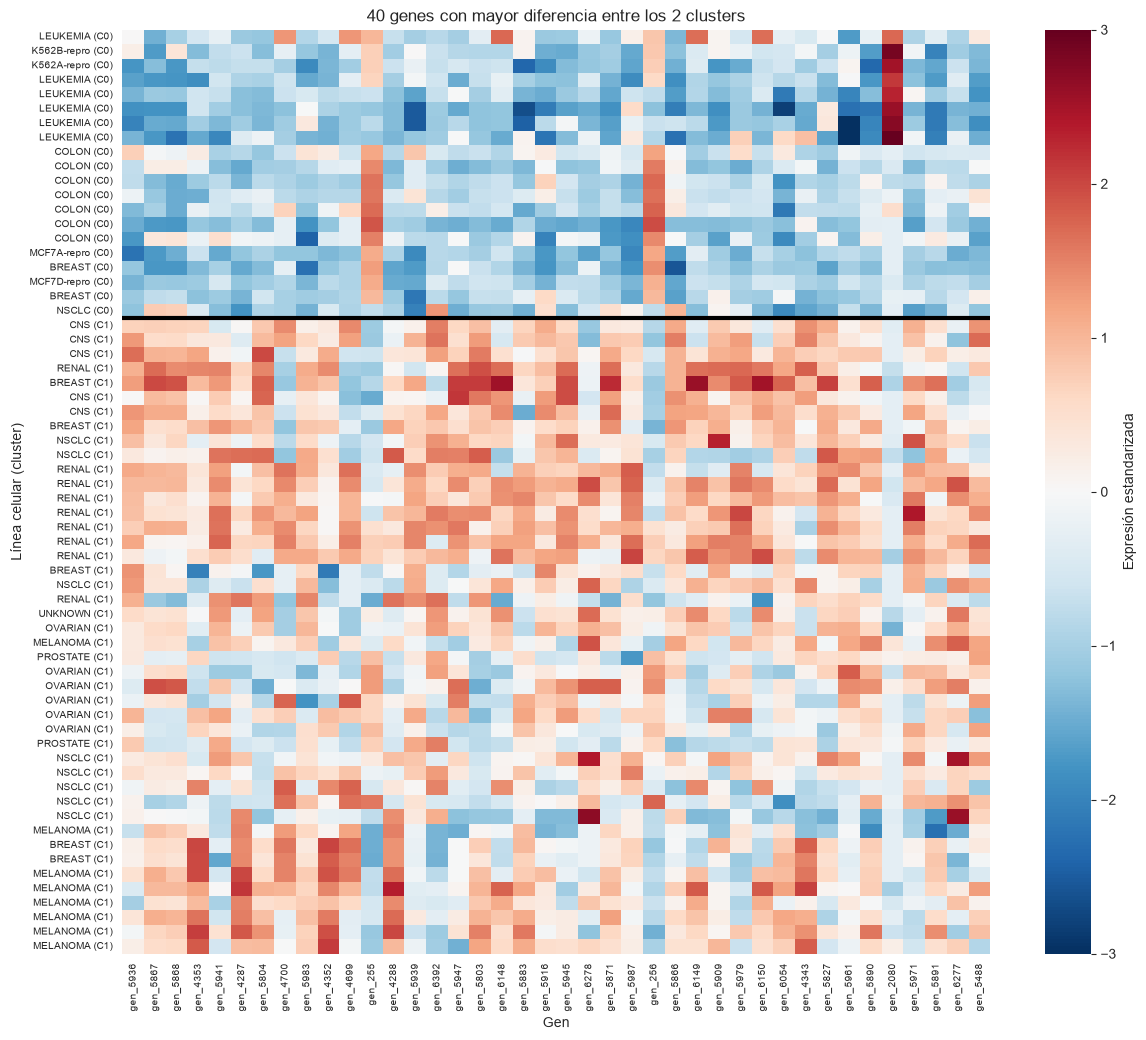

In [120]:
# 5. Estandarizar los 40 genes
datos_heat = pd.DataFrame(StandardScaler().fit_transform(X_nci[genes_relevantes]),
                          columns=genes_relevantes)

# 6. Ordenar las líneas celulares por cluster
orden = np.argsort(clusters_2, kind='stable')
datos_heat = datos_heat.iloc[orden]
datos_heat.index = [f'{etiquetas_cancer.iloc[i]} (C{clusters_2[i]})' for i in orden]

plt.figure(figsize=(14, 12))
sns.heatmap(datos_heat, cmap='RdBu_r', center=0, vmin=-3, vmax=3,
            cbar_kws={'label': 'Expresión estandarizada'}, yticklabels=True)
corte = np.bincount(clusters_2)[0]
plt.axhline(corte, color='black', linewidth=3)      # línea que separa los 2 clusters
plt.title(f'{N_GENES} genes con mayor diferencia entre los 2 clusters')
plt.xlabel('Gen')
plt.ylabel('Línea celular (cluster)')
plt.yticks(fontsize=7)
plt.xticks(fontsize=7)
plt.show()

**¿Qué vemos?**
- La línea negra separa los dos clusters. Se nota un **cambio claro de color**: la mayoría de estos 40 genes están en **rojo** (alta expresión) en el grupo grande y en **azul** (baja expresión) en el grupo pequeño. Solo 3 genes muestran el patrón contrario: `gen_255` y `gen_256` están altos sobre todo en **colon**, y `gen_2080` en **leucemia** y sus réplicas K562.
- Es decir, la diferencia entre los clusters no se debe a un solo gen: hay un **conjunto de genes que se "prenden" o "apagan" juntos**, y K-means lo detectó sin saber nada de biología.
- Dentro de cada cluster también hay variaciones (por ejemplo, filas más claras u oscuras). Esas son las diferencias que, con más clusters, dan lugar a subgrupos como melanoma o leucemia.

En un estudio real, estos genes serían **candidatos** para investigar qué distingue biológicamente a cada grupo de tumores.

### Conclusiones de la Parte 2
- Aplicar K-means directo sobre miles de genes da clusters **poco claros** y difíciles de visualizar.
- **Estandarizar + PCA** reduce el ruido y deja pocas variables que resumen la información más importante. Con 5 PCs los clusters quedan mucho mejor definidos (el silhouette pasa de ≈ 0.08 a ≈ 0.34).
- Para elegir $k$ combinamos métricas (WCV, silhouette) con **qué tan interpretables** son los grupos. Elegimos $k = 4$.
- Los clusters tienen **sentido biológico**: melanoma, leucemia, colon y renal/CNS quedan bien agrupados, aunque K-means nunca vio las etiquetas.

---
# Parte 3. Hierarchical clustering en NCI60

## 3.1 ¿Por qué otro método?

En la Parte 2 tuvimos que **decidir $k$ antes** de correr K-means, y para elegirlo probamos varios valores y comparamos métricas. Aun así, la respuesta no fue obvia: el silhouette casi no cambiaba entre 3, 4 y 5 clusters. **¿Estamos seguros de que 4 es el número correcto?** No del todo.

El **hierarchical clustering** (clustering jerárquico) no necesita que fijemos $k$ al inicio. En lugar de una sola partición, genera un **árbol (dendrograma)** con **todas las agrupaciones posibles**, desde 1 cluster hasta $n$ clusters. Después, mirando el árbol, decidimos cuántos grupos tomar.

**Datos.** Usamos los mismos **5 componentes principales** de la Parte 2 (`pcs_sel`), para comparar ambos métodos sobre los mismos datos.

## 3.2 El algoritmo

El tipo más común es el **aglomerativo** (de abajo hacia arriba):

1. Empezamos con cada observación como **su propio cluster** ($n$ clusters).
2. Calculamos la **disimilitud** (qué tan diferentes son) entre todos los pares de clusters.
3. **Unimos** los dos clusters más parecidos. Ahora hay un cluster menos.
4. Repetimos los pasos 2 y 3 hasta que todo queda en **un solo cluster**.

Cada unión se dibuja en el dendrograma a la **altura** igual a la disimilitud entre los dos clusters que se unieron.

Para correrlo hay que elegir dos cosas:
- **Métrica de disimilitud:** cómo medimos la diferencia entre **dos observaciones** (por ejemplo, distancia Euclidiana).
- **Método de *linkage*:** cómo medimos la diferencia entre **dos grupos** de observaciones (lo vemos en la sección 3.6).

Usamos la función `linkage` de `scipy`, que hace todo el proceso y guarda el historial de uniones.

## 3.3 Primer dendrograma: *complete* + Euclidiana

**Qué hacemos.** Corremos el clustering jerárquico con método `'complete'` y métrica `'euclidean'`, y graficamos el dendrograma en **un solo color**. Cada hoja lleva el **tipo de cáncer** de esa línea celular, para poder ver qué tipos se juntan.

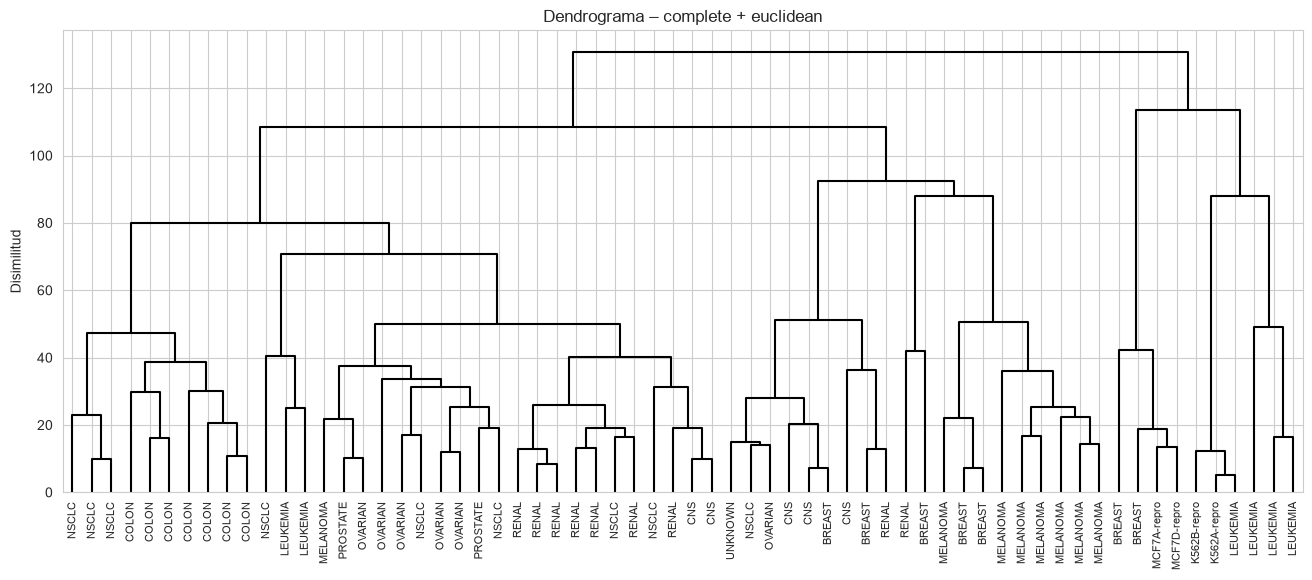

In [121]:
hc_complete = linkage(pcs_sel, method='complete', metric='euclidean')

def graficar_dendrograma(Z, titulo, color_threshold=0, linea=None):
    plt.figure(figsize=(16, 6))
    dendrogram(Z, labels=etiquetas_cancer.values, leaf_font_size=8,
               color_threshold=color_threshold,
               above_threshold_color='black' if color_threshold == 0 else 'gray')
    if linea is not None:
        plt.axhline(linea, color='red', linestyle='--', label=f'Corte = {linea:.1f}')
        plt.legend()
    plt.title(titulo)
    plt.ylabel('Disimilitud')
    plt.show()

graficar_dendrograma(hc_complete, 'Dendrograma – complete + euclidean')

### ¿Cómo se lee un dendrograma?

- Cada **hoja** (abajo) es una observación, en este caso una línea celular.
- Al subir, las hojas se **unen en ramas**: se unen las observaciones (o grupos) que son **parecidas** entre sí.
- **Mientras más abajo** sea la unión, **más parecidas** son esas observaciones. Uniones muy altas significan grupos muy diferentes.
- El **eje y** es la disimilitud. Ojo: el eje x **no** mide nada; dos hojas que quedan juntas horizontalmente no necesariamente son parecidas, lo que importa es la **altura** donde se unen.

**¿Qué vemos?**
- Varias líneas del mismo tipo se unen **muy abajo**: por ejemplo, las de **melanoma**, **colon** y **renal** aparecen juntas en sus propias ramas.
- Las **réplicas** se unen **muy abajo** con su línea original: **K562** con **leucemia** y **MCF7** con **mama**. Tiene sentido, porque son prácticamente la misma muestra.
- En la parte alta hay pocas uniones grandes, que separan grupos muy distintos. Esas son las que definen los clusters cuando cortamos el árbol.

## 3.4 Cortar el árbol: 2, 3 y 4 clusters

**Qué hacemos.** Volvemos a graficar el dendrograma, ahora **a colores**, cambiando el umbral de color (`color_threshold`). Todo lo que se une **por debajo** del umbral recibe un mismo color, así que cada color es un cluster. Es lo mismo que **cortar el árbol** con una línea horizontal a esa altura.

**Cómo elegimos el umbral.** `linkage` guarda la altura de cada unión. Para obtener $k$ clusters, cortamos entre la altura de la unión número $k$ y la $k-1$ contando desde arriba (usamos el punto medio entre ambas).

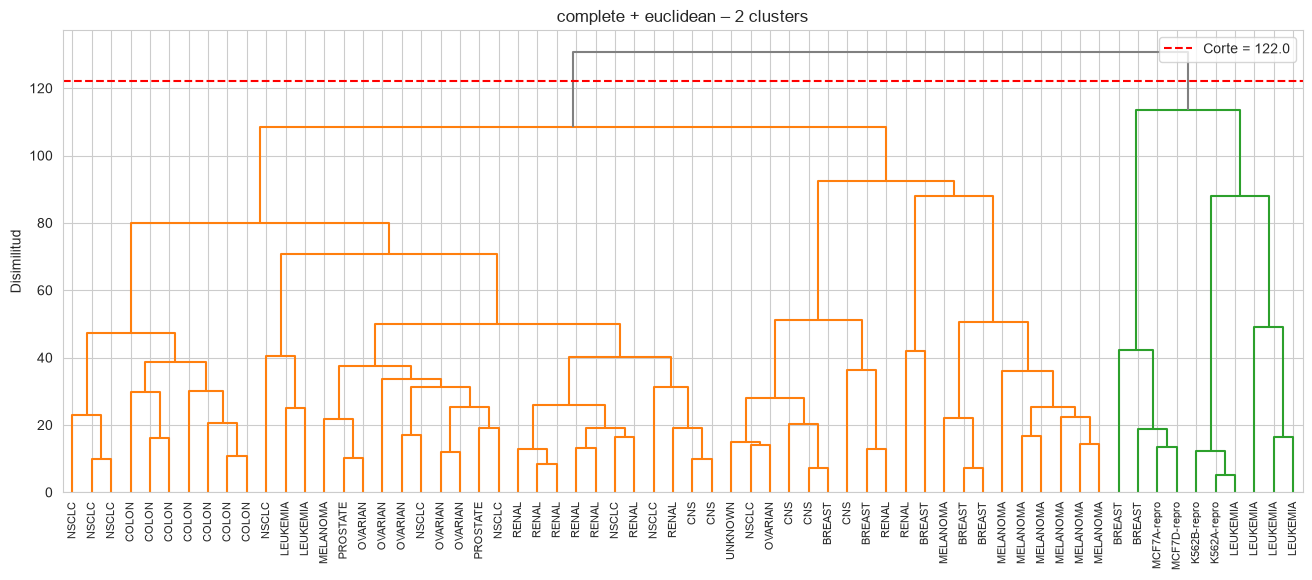

2 clusters → tamaños: [54 10]


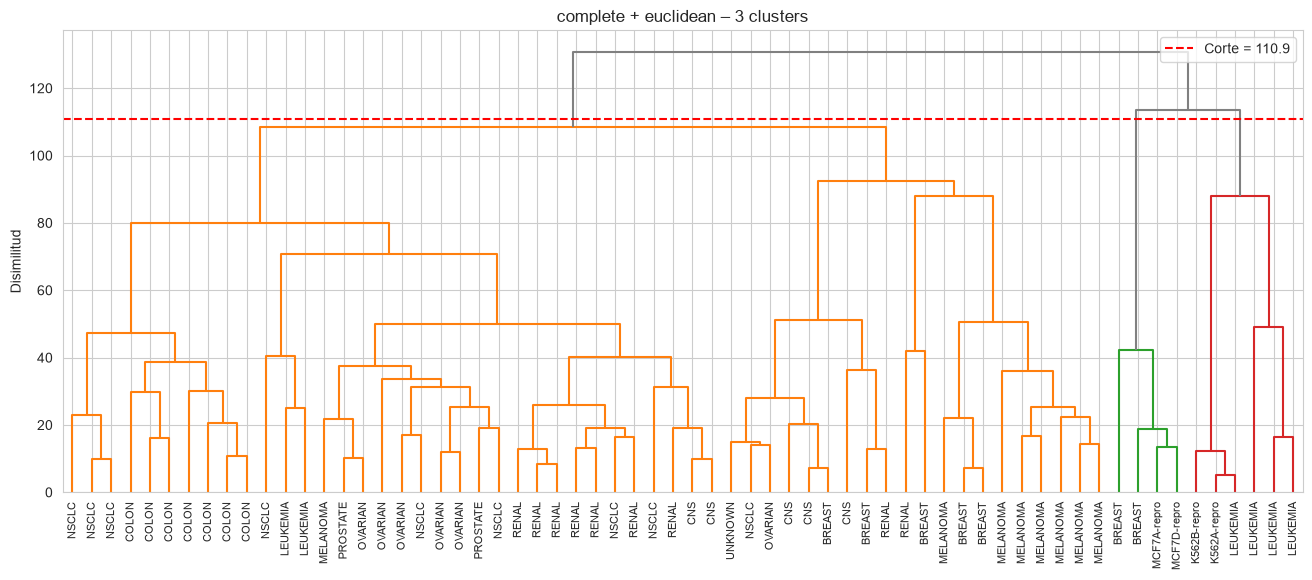

3 clusters → tamaños: [54  4  6]


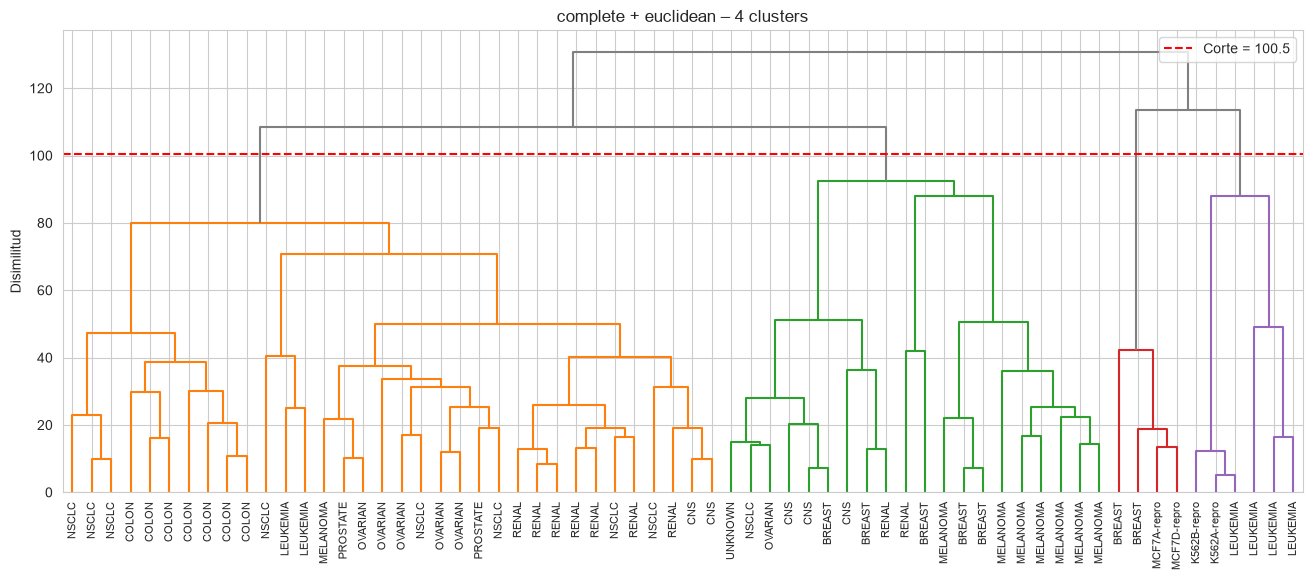

4 clusters → tamaños: [34 20  4  6]


In [122]:
def umbral_para_k(Z, k):
    # alturas de las uniones más altas: Z[-1] es la última unión (la más alta)
    return (Z[-k, 2] + Z[-(k - 1), 2]) / 2

for k in [2, 3, 4]:
    t = umbral_para_k(hc_complete, k)
    graficar_dendrograma(hc_complete, f'complete + euclidean – {k} clusters',
                         color_threshold=t, linea=t)
    print(f'{k} clusters → tamaños: {np.bincount(fcluster(hc_complete, k, criterion="maxclust"))[1:]}')

> `fcluster(..., criterion='maxclust')` corta el árbol para obtener exactamente $k$ clusters y regresa la etiqueta de cada observación. Lo usamos para ver el tamaño de cada cluster.

**¿Qué vemos?**
- **2 clusters (tamaños 54 y 10):** el primer corte separa un grupo pequeño de 10 líneas (4 leucemias, sus réplicas K562, las réplicas de mama MCF7 y 2 líneas de mama) del resto.
- **3 clusters (54, 4, 6):** ese grupo pequeño se divide en dos: uno con **leucemias + K562** y otro con **MCF7 + mama**. El grupo grande no cambia.
- **4 clusters (34, 20, 4, 6):** ahora sí se parte el grupo grande, en uno con **melanoma** y parte de mama, y otro con el resto.

Fíjate en algo importante: **al bajar el corte, los clusters solo se dividen, nunca se mezclan**. Los 4 clusters están **dentro** de los 3, y los 3 dentro de los 2. Por eso se llama **jerárquico**.

### Ventajas y desventajas de que sea jerárquico

**Ventaja:** con un solo árbol vemos **todas** las opciones de número de clusters. K-means, en cambio, necesita correr de nuevo para cada $k$.

**Desventaja:** los grupos reales **no siempre están anidados**. Ejemplo: personas de **3 países** con **2 tipos de profesión**.
- La mejor división en 2 grupos podría ser por **profesión**.
- La mejor división en 3 grupos podría ser por **país**.

Los grupos por país no salen de partir los grupos por profesión, así que un árbol jerárquico **no puede** representar bien ambos. En casos así, K-means (que calcula cada $k$ por separado) puede dar mejores grupos.

## 3.5 Cambiar la métrica: *complete* + correlación

**Qué hacemos.** Repetimos el proceso con método `'complete'` pero ahora con métrica `'correlation'`, y comparamos el dendrograma con el anterior.

**Diferencia entre métricas.** Pensemos en H-E-B analizando a sus clientes:
- **Distancia Euclidiana:** agrupa por **cuánto** compran. Dos clientes son parecidos si sus cantidades son similares (los de alto volumen juntos y los de bajo volumen juntos), sin importar qué productos compran.
- **Correlación:** agrupa por **qué** compran. Dos clientes son parecidos si sus compras **suben y bajan en los mismos productos**, aunque uno compre mucho y el otro poco.

En nuestro caso, la correlación junta líneas celulares cuyo **patrón** a lo largo de los 5 componentes es parecido, aunque sus valores sean de distinta magnitud.

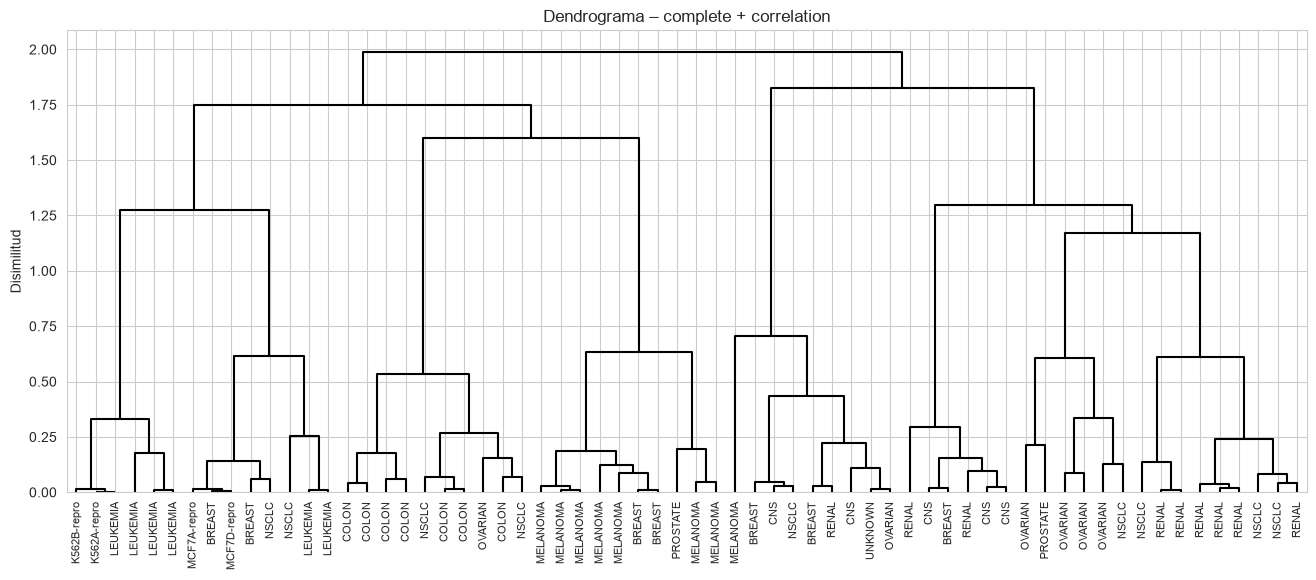

2 clusters → tamaños: [34 30]
3 clusters → tamaños: [34  9 21]
4 clusters → tamaños: [14 20  9 21]


In [123]:
hc_correlacion = linkage(pcs_sel, method='complete', metric='correlation')
graficar_dendrograma(hc_correlacion, 'Dendrograma – complete + correlation')

for k in [2, 3, 4]:
    print(f'{k} clusters → tamaños: {np.bincount(fcluster(hc_correlacion, k, criterion="maxclust"))[1:]}')

**¿Qué vemos?**
- El **eje y cambia de escala**: la disimilitud por correlación es $1 - r$, así que va de 0 (patrón idéntico) a 2 (patrón opuesto). Por eso las alturas ya no se comparan directamente con el dendrograma anterior.
- Los grupos quedan **más balanceados**: con 2 clusters los tamaños son 34 y 30 (con Euclidiana eran 54 y 10). Con correlación ya no importa qué tan "extremo" es un punto, solo su patrón, así que ningún grupo pequeño se separa solo por estar lejos.
- Se mantienen juntos algunos tipos (**leucemia** con sus réplicas, **renal**), pero aparecen combinaciones nuevas, como **melanoma y colon en la misma rama**.

**Conclusión:** la métrica cambia por completo la forma del árbol. Hay que elegirla según **qué significa "parecido"** en el problema.

## 3.6 Cambiar el *linkage*: *average* + Euclidiana

**Qué es el *linkage*.** Comparar dos observaciones es fácil: es un solo número. Pero, ¿cómo comparamos **dos grupos** de varias observaciones? Hay muchas distancias posibles entre sus puntos. El método de *linkage* decide cuál usar:

| Método | Cómo mide la disimilitud entre el grupo A y el grupo B |
|---|---|
| **Complete** | La **mayor** distancia entre un punto de A y uno de B |
| **Single** | La **menor** distancia entre un punto de A y uno de B |
| **Average** | El **promedio** de todas las distancias entre puntos de A y de B |
| **Ward** | Une los grupos que **menos aumentan** la variación dentro de los clusters (solo con distancia Euclidiana) |

**Qué hacemos.** Corremos el método `'average'` con métrica `'euclidean'` y lo comparamos con los dendrogramas anteriores.

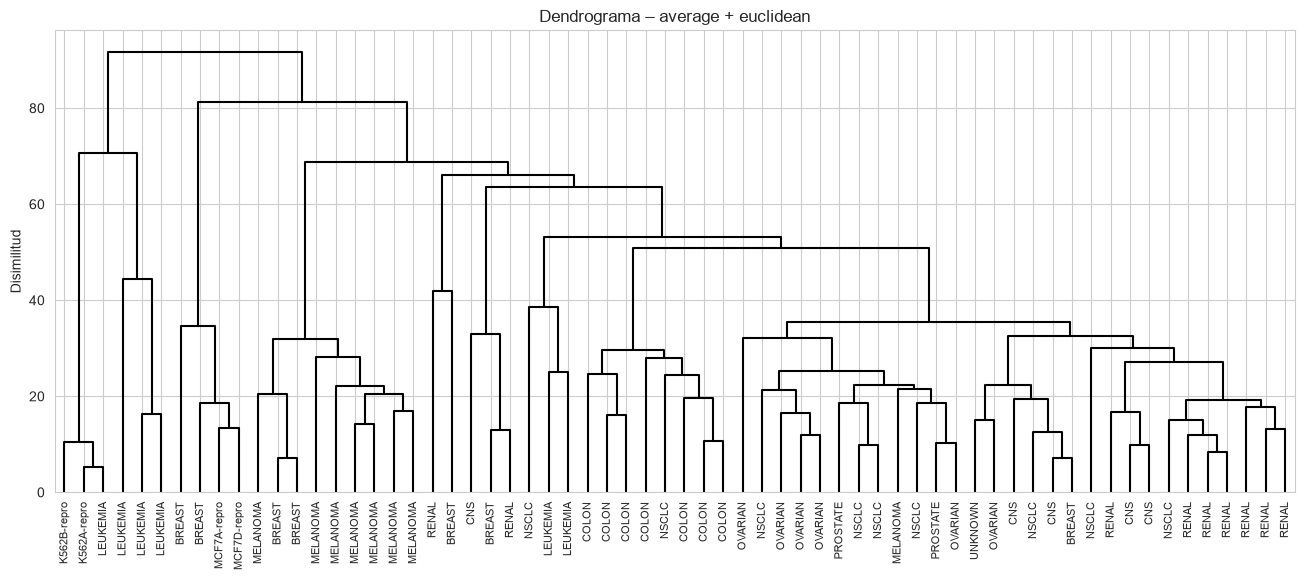

2 clusters → tamaños: [ 6 58]
3 clusters → tamaños: [ 6  4 54]
4 clusters → tamaños: [ 3  3  4 54]


In [124]:
hc_average = linkage(pcs_sel, method='average', metric='euclidean')
graficar_dendrograma(hc_average, 'Dendrograma – average + euclidean')

for k in [2, 3, 4]:
    print(f'{k} clusters → tamaños: {np.bincount(fcluster(hc_average, k, criterion="maxclust"))[1:]}')

**¿Qué vemos?**
- Las uniones de arriba quedan a **menor altura** que con *complete*. Es lógico: el promedio de las distancias siempre es menor o igual que la distancia máxima.
- El árbol es **menos balanceado**: con 4 clusters tenemos un grupo gigante de **54** líneas y tres grupos muy pequeños (3, 3 y 4). *Average* tiende a ir separando de uno en uno los grupos pequeños más alejados (leucemias, réplicas) y deja todo lo demás junto.
- *Complete*, en cambio, castiga unir grupos que tengan **aunque sea un par de puntos lejanos**, por eso forma clusters más compactos y de tamaño más parecido.

**Conclusión:** en la práctica, **complete** y **average** son los más usados porque dan árboles más balanceados que *single*, que tiende a formar "cadenas" donde los puntos se van pegando uno a uno a un mismo grupo. Para estos datos, *complete* da grupos más útiles para interpretar.

## 3.7 Tipos de cáncer vs clusters

**Qué hacemos.** Tomamos el dendrograma de **complete + Euclidiana**, lo cortamos en **4 clusters** (el mismo número que elegimos para K-means) y contamos cuántas líneas de cada tipo de cáncer quedan en cada cluster.

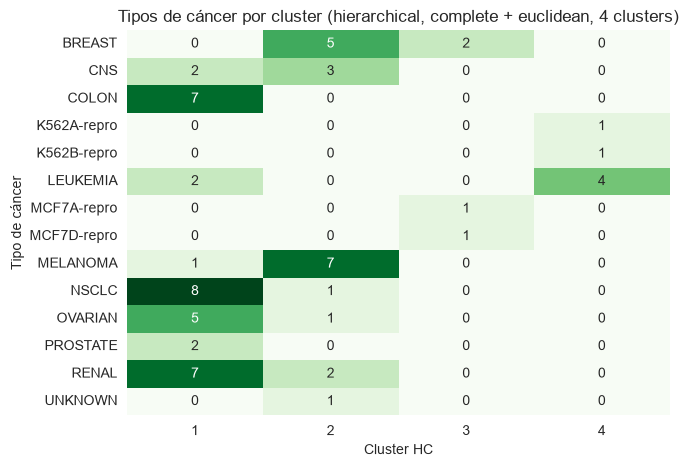

In [125]:
clusters_hc = fcluster(hc_complete, 4, criterion='maxclust')

tabla_hc = pd.crosstab(etiquetas_cancer, clusters_hc, rownames=['Tipo de cáncer'], colnames=['Cluster HC'])
sns.heatmap(tabla_hc, annot=True, cmap='Greens', cbar=False)
plt.title('Tipos de cáncer por cluster (hierarchical, complete + euclidean, 4 clusters)')
plt.show()

**¿Qué vemos?**
- Un cluster pequeño agrupa **leucemia** (4 de 6) con sus réplicas **K562**.
- Otro cluster pequeño contiene solo las réplicas **MCF7** y 2 líneas de **mama**: este método separa a esa familia de mama como un grupo propio.
- Un cluster de 20 líneas reúne casi todo **melanoma** (7 de 8) y la mayoría de **mama** (5 de 7).
- El cluster más grande (34 líneas) mezcla **colon, NSCLC, renal, ovario**, 2 leucemias y otros. Aquí este método **no logra separar** tipos que K-means sí separaba (por ejemplo, colon y renal quedaron juntos).

## 3.8 Comparación: K-means vs hierarchical

**Qué hacemos.** Cruzamos los 4 clusters de K-means (Parte 2) con los 4 clusters jerárquicos. Si ambos métodos encontraran los mismos grupos, cada fila tendría un solo número distinto de 0.

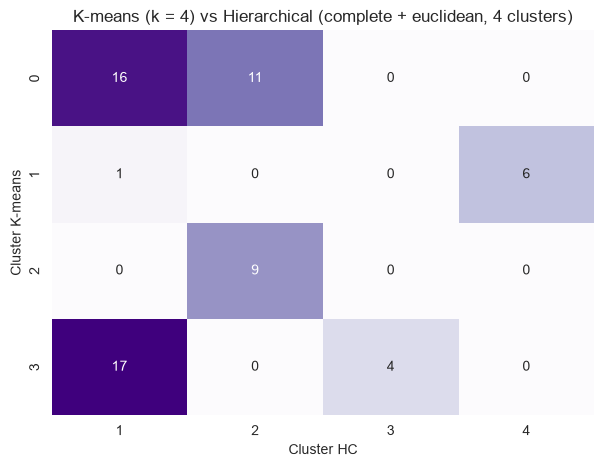

In [126]:
tabla_comp = pd.crosstab(pd.Series(clusters_km, name='Cluster K-means'),
                         pd.Series(clusters_hc, name='Cluster HC'))
sns.heatmap(tabla_comp, annot=True, cmap='Purples', cbar=False)
plt.title('K-means (k = 4) vs Hierarchical (complete + euclidean, 4 clusters)')
plt.show()

**¿Qué vemos?** *(Los números de cluster de K-means pueden cambiar entre versiones; describimos cada grupo por su contenido.)*
- **Coinciden bien:**
  - El cluster de **melanoma** de K-means (9 líneas) cae **completo** en un solo cluster jerárquico.
  - El cluster de **leucemia** de K-means (7 líneas) cae casi completo (6 de 7) en el cluster jerárquico de leucemia.
- **No coinciden:**
  - El cluster **renal/CNS** de K-means se **reparte** entre dos clusters jerárquicos (16 y 11 líneas).
  - El cluster de **colon** de K-means queda casi todo en el cluster grande jerárquico, salvo las 4 líneas de **MCF7 + mama**, que el jerárquico separó aparte.

**¿Por qué difieren?** Los métodos buscan cosas distintas:
- **K-means** busca $k$ grupos que minimicen la variación total, viendo todas las observaciones a la vez.
- **Hierarchical** une pares paso a paso y **nunca deshace** una unión. Si dos líneas se unen temprano, quedan juntas para siempre, aunque después eso no sea lo mejor para el grupo completo.

Los grupos **más fuertes** (melanoma y leucemia) aparecen con los dos métodos. Cuando dos métodos distintos coinciden, podemos confiar más en que ese grupo es real. Los grupos que cambian según el método (renal, colon, NSCLC) son los menos claros en los datos.

---
# Conclusiones generales

1. **K-means** es simple y rápido: alterna entre calcular centroides y reasignar puntos. Pero necesita **fijar $k$**, depende del **inicio aleatorio** (por eso se usa `n_init`) y solo garantiza un óptimo local.
2. En datos con **muchas variables** (6,830 genes), **estandarizar y aplicar PCA** antes de agrupar reduce el ruido y produce clusters mucho mejor definidos.
3. **Hierarchical clustering** no necesita $k$ por adelantado: el **dendrograma** muestra todas las opciones y elegimos dónde cortar. A cambio, los clusters siempre quedan **anidados**, lo cual no siempre refleja la realidad.
4. En el jerárquico, la **métrica** (Euclidiana vs correlación) y el **linkage** (complete, average, etc.) cambian mucho el resultado. Hay que elegirlos según qué significa "parecido" en el problema.
5. En NCI60, ambos métodos encontraron, **sin ver las etiquetas**, grupos con sentido biológico. **Melanoma** y **leucemia** aparecen siempre como grupos propios. Otros tipos (mama, NSCLC, ovario) se reparten entre clusters, lo que indica perfiles genéticos más variados.
6. El clustering **no tiene una única respuesta correcta**. Es una herramienta para **explorar**: conviene probar varios métodos y quedarse con los grupos que se mantienen estables.